# ¿Cómo decidir: modelo lineal o no lineal?

Este notebook es una guía de estudio **detallada** (pero accesible) para ayudarte a decidir
si en un problema de clasificación conviene usar un modelo **lineal** (ej. LogisticRegression)
o un modelo **no lineal** (ej. SVC con kernel RBF).

**Objetivos**

- Generar datasets de ejemplo (lineal y no lineal).
- Entrenar y comparar **Logistic Regression** vs **SVC (RBF)**.
- Visualizar fronteras de decisión y métricas (accuracy, AUC).
- Entregar una receta práctica para tomar la decisión.


## 1) Librerías y notas sobre el entorno

Este notebook usa `scikit-learn`, `numpy`, `matplotlib` y `seaborn`.

Si falta alguna librería, instálala con:
```
pip install scikit-learn matplotlib seaborn
```


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_classification, make_circles
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.metrics import accuracy_score, roc_auc_score, roc_curve

sns.set(style='whitegrid')
np.random.seed(42)
print('Librerías cargadas correctamente')

Librerías cargadas correctamente


## 2) Crear datasets de ejemplo

- **Dataset A (Lineal)**: diseñado para que las clases sean separables con una línea.
- **Dataset B (No lineal)**: círculos concéntricos, claramente no separables por una recta.


In [9]:
# Dataset linealmente separable
X_lin, y_lin = make_classification(n_samples=400, n_features=2,
                                   n_redundant=0, n_informative=2,
                                   n_clusters_per_class=1, flip_y=0.03, random_state=42)

# Dataset no lineal (círculos)
X_nonlin, y_nonlin = make_circles(n_samples=400, factor=0.4, noise=0.05, random_state=42)

print('Shapes lineal:', X_lin.shape, y_lin.shape)
print('Shapes no-lineal:', X_nonlin.shape, y_nonlin.shape)

Shapes lineal: (400, 2) (400,)
Shapes no-lineal: (400, 2) (400,)


## 3) Visualizar los datasets

Observa si a simple vista parece que se puede trazar una **línea** que separe las clases.


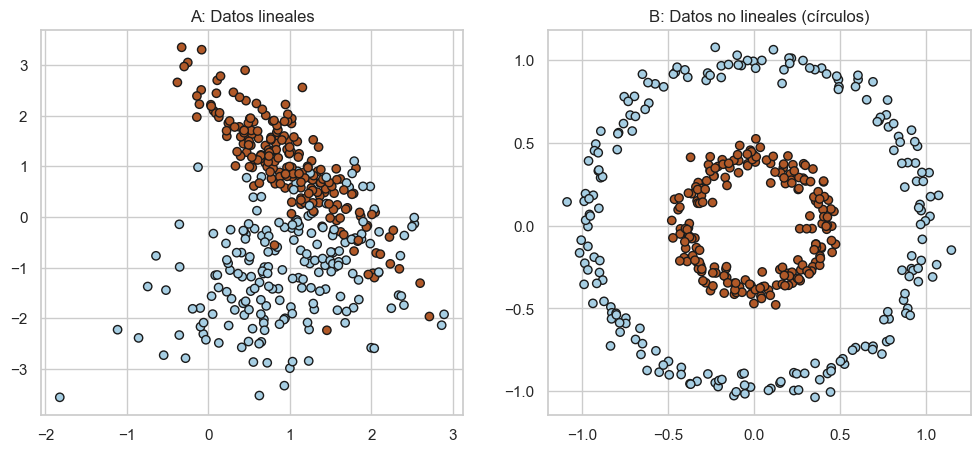

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12,5))
axes[0].scatter(X_lin[:,0], X_lin[:,1], c=y_lin, cmap=plt.cm.Paired, edgecolor='k')
axes[0].set_title('A: Datos lineales')

axes[1].scatter(X_nonlin[:,0], X_nonlin[:,1], c=y_nonlin, cmap=plt.cm.Paired, edgecolor='k')
axes[1].set_title('B: Datos no lineales (círculos)')
plt.show()

### Función auxiliar

Usaremos una función para dibujar la frontera de decisión de cualquier clasificador entrenado.


In [4]:
def plot_decision_boundary(model, X, y, ax, title, mesh_step=0.02):
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, mesh_step),
                         np.arange(y_min, y_max, mesh_step))
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.25, cmap=plt.cm.Paired)
    ax.scatter(X[:, 0], X[:, 1], c=y, edgecolor='k', cmap=plt.cm.Paired)
    ax.set_title(title)
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)

print('Función auxiliar lista.')

Función auxiliar lista.


## 4) Entrenar modelos y comparar (accuracy + cross-validation)

Entrenaremos **LogisticRegression** (lineal) y **SVC(kernel='rbf')** (no lineal) en ambos datasets.


In [5]:
models = {
    'LogisticRegression': LogisticRegression(max_iter=1000),
    'SVC_RBF': SVC(kernel='rbf', probability=True)
}

results = {}
for name, model in models.items():
    scores_lin = cross_val_score(model, X_lin, y_lin, cv=5, scoring='accuracy')
    scores_nonlin = cross_val_score(model, X_nonlin, y_nonlin, cv=5, scoring='accuracy')
    results[name] = {
        'lin_mean_acc': scores_lin.mean(), 'lin_std': scores_lin.std(),
        'nonlin_mean_acc': scores_nonlin.mean(), 'nonlin_std': scores_nonlin.std()
    }

import pandas as pd
pd.DataFrame(results).T

,lin_mean_acc,lin_std,nonlin_mean_acc,nonlin_std
LogisticRegression,0.8775,0.018371,0.47,0.03221
SVC_RBF,0.8725,0.024238,1.00,0.00000


## 5) Fronteras de decisión (entrenando con todo el dataset)

Entrenamos cada modelo con todo el dataset para visualizar cómo separan las clases.


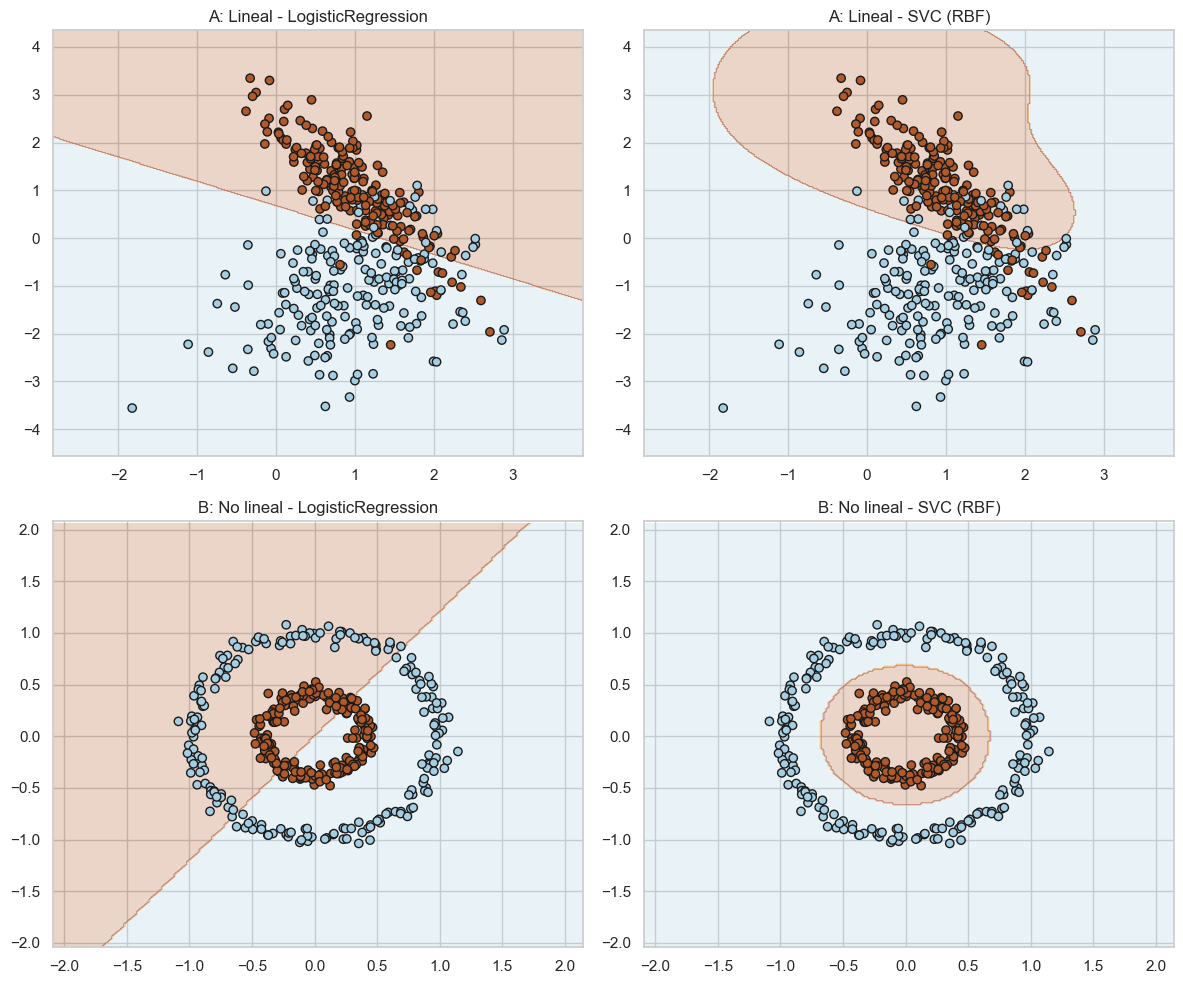

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(12,10))

# A: linear dataset
log_reg_lin = LogisticRegression(max_iter=1000).fit(X_lin, y_lin)
svc_rbf_lin = SVC(kernel='rbf').fit(X_lin, y_lin)
plot_decision_boundary(log_reg_lin, X_lin, y_lin, axes[0,0], 'A: Lineal - LogisticRegression')
plot_decision_boundary(svc_rbf_lin, X_lin, y_lin, axes[0,1], 'A: Lineal - SVC (RBF)')

# B: non-linear dataset
log_reg_nonlin = LogisticRegression(max_iter=1000).fit(X_nonlin, y_nonlin)
svc_rbf_nonlin = SVC(kernel='rbf').fit(X_nonlin, y_nonlin)
plot_decision_boundary(log_reg_nonlin, X_nonlin, y_nonlin, axes[1,0], 'B: No lineal - LogisticRegression')
plot_decision_boundary(svc_rbf_nonlin, X_nonlin, y_nonlin, axes[1,1], 'B: No lineal - SVC (RBF)')

plt.tight_layout()
plt.show()

## 6) ROC y AUC (comparación de probabilidades)

Aunque accuracy es útil, AUC mide la capacidad del modelo para ordenar ejemplos (útil si hay desbalance).


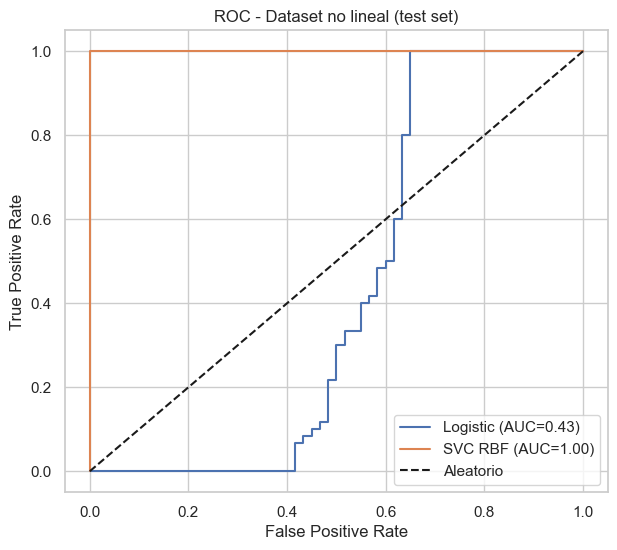

AUC Logistic: 0.4291666666666667
AUC SVC RBF: 1.0


In [7]:
# Tomamos dataset no lineal para ver ROC comparativa
X_train, X_test, y_train, y_test = train_test_split(X_nonlin, y_nonlin, test_size=0.3, random_state=42)
log = LogisticRegression(max_iter=1000).fit(X_train, y_train)
svc = SVC(kernel='rbf', probability=True).fit(X_train, y_train)

probs_log = log.predict_proba(X_test)[:,1]
probs_svc = svc.predict_proba(X_test)[:,1]

auc_log = roc_auc_score(y_test, probs_log)
auc_svc = roc_auc_score(y_test, probs_svc)

fpr_log, tpr_log, _ = roc_curve(y_test, probs_log)
fpr_svc, tpr_svc, _ = roc_curve(y_test, probs_svc)

plt.figure(figsize=(7,6))
plt.plot(fpr_log, tpr_log, label=f'Logistic (AUC={auc_log:.2f})')
plt.plot(fpr_svc, tpr_svc, label=f'SVC RBF (AUC={auc_svc:.2f})')
plt.plot([0,1],[0,1],'k--', label='Aleatorio')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC - Dataset no lineal (test set)')
plt.legend()
plt.grid(True)
plt.show()

print('AUC Logistic:', auc_log)
print('AUC SVC RBF:', auc_svc)

## 7) Receta práctica (checklist) para decidir si probar un modelo lineal o no lineal

1. **Visualiza tus datos (si son 2D)**: ¿puedes imaginar una línea que separe las clases? Si sí, prueba un modelo lineal primero.

2. **Empieza con un baseline lineal** (LogisticRegression): es rápido, interpretable y sirve como referencia.

3. **Estandariza/normaliza** tus features cuando uses SVM o métodos basados en distancia (StandardScaler).

4. **Si el linear falla**, prueba SVC-RBF u otros modelos no lineales (RandomForest, XGBoost).

5. **Usa validación cruzada (k-fold)** para comparar modelos robustamente.

6. **Observa ROC y PR** si las clases están desbalanceadas.

7. **Considera recursos**: SVC-RBF puede ser lento en datasets grandes.

8. **Si necesitas interpretabilidad**, prefiere lineales o usa explicadores (SHAP/LIME) para modelos complejos.


## 8) Tips prácticos y errores comunes

- **Feature scaling**: importante para SVM. LogisticRegression también se beneficia.
- **Outliers**: afectan modelos lineales.
- **Interacciones**: si sospechas interacciones entre features, añade términos polinómicos o usa modelos no lineales.
- **Sobreajuste**: regula (C, gamma) y usa CV.


## 9) Conclusión

Empieza lineal (rápido y interpretable). Si la performance es insuficiente o los datos muestran fronteras complejas, prueba modelos no lineales y compara con validación cruzada.


Modifica parámetros y vuelve a ejecutar — la mejor forma de decidir es **comparando**.
